In [32]:
# %% 1. Import & baca data
import pandas as pd

data = pd.read_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2022.csv")
print(f"Ukuran awal: {data.shape}")

# %% 2. Filter dulu: hanya DIABETE4 == 1
print(data['DIABETE4'].value_counts(dropna=False))

data = data[data['DIABETE4'] == 1].copy()
data = data.reset_index(drop=True)

print(f"Ukuran setelah filter: {data.shape}")
print(data['DIABETE4'].value_counts())

Ukuran awal: (445132, 328)
DIABETE4
3.0    368722
1.0     61158
4.0     10329
2.0      3836
7.0       763
9.0       321
NaN         3
Name: count, dtype: int64
Ukuran setelah filter: (61158, 328)
DIABETE4
1.0    61158
Name: count, dtype: int64


In [33]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_SMOKGRP,_LCSREC,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,1.0,2032022,2,3,2022,1100.0,2022000001,2.022000e+09,1.0,...,4.0,NaN,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
1,1.0,1.0,2112022,2,11,2022,1100.0,2022000006,2.022000e+09,1.0,...,4.0,NaN,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,2.0
2,1.0,1.0,2072022,2,7,2022,1100.0,2022000010,2.022000e+09,1.0,...,4.0,NaN,1.0,3.000000e+00,1.0,2.300000e+01,1.0,1.0,1.0,9.0
3,1.0,2.0,2152022,2,15,2022,1100.0,2022000018,2.022000e+09,1.0,...,3.0,NaN,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
4,1.0,3.0,3032022,3,3,2022,1100.0,2022000027,2.022000e+09,1.0,...,3.0,2.0,1.0,3.000000e+00,1.0,2.300000e+01,1.0,1.0,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61153,78.0,11.0,12202022,12,20,2022,1200.0,2022001483,2.022001e+09,NaN,...,4.0,NaN,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0
61154,78.0,11.0,1142023,1,14,2023,1100.0,2022001497,2.022001e+09,NaN,...,4.0,NaN,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,2.0
61155,78.0,11.0,1142023,1,14,2023,1200.0,2022001503,2.022002e+09,NaN,...,NaN,NaN,9.0,9.000000e+02,9.0,9.990000e+04,9.0,9.0,9.0,NaN
61156,78.0,11.0,12162022,12,16,2022,1100.0,2022001512,2.022002e+09,NaN,...,4.0,NaN,1.0,9.000000e+01,2.0,6.300000e+02,1.0,NaN,NaN,2.0


In [34]:
# %% 3. Cek missing value (dihitung dari data diabetes saja)
missing = data.isnull().sum()
missing_pct = (missing / len(data)) * 100

missing_df = pd.DataFrame({
    'jumlah_kosong': missing,
    'persen_kosong': missing_pct.round(2)
})
missing_df = (missing_df[missing_df['jumlah_kosong'] > 0]
              .sort_values('persen_kosong', ascending=False))

print(f"Total fitur           : {data.shape[1]}")
print(f"Fitur yang ada kosong : {len(missing_df)}")
print(missing_df.head(20))

Total fitur           : 328
Fitur yang ada kosong : 252
          jumlah_kosong  persen_kosong
COLGHOUS          61155         100.00
COLGSEX1          61155         100.00
PREDIAB2          61157         100.00
PDIABTS1          61158         100.00
HAVECFS           61158         100.00
WORKCFS           61158         100.00
TOLDCFS           61158         100.00
CCLGHOUS          61117          99.93
HPVADSHT          61093          99.89
MENTECIG          60987          99.72
NOBCUSE8          60942          99.65
RCSXBRTH          60887          99.56
WHEREGET          60817          99.44
CSRVCTL2          60794          99.40
USEMRJN4          60781          99.38
TYPCNTR9          60767          99.36
BRTHCNT4          60767          99.36
HPVADVC4          60735          99.31
CASTHNO2          60593          99.08
BCPREFER          60549          99.00


In [35]:
# %% 4. Hapus fitur dengan missing value > 15%
cols_to_drop = missing_pct[missing_pct >= 20].index

print(f"Jumlah fitur yang dihapus: {len(cols_to_drop)}")
print(missing_pct[cols_to_drop].sort_values(ascending=False).head(20))

data = data.drop(columns=cols_to_drop)
print(f"Sisa fitur: {data.shape[1]}")


Jumlah fitur yang dihapus: 208
PDIABTS1    100.000000
WORKCFS     100.000000
HAVECFS     100.000000
TOLDCFS     100.000000
PREDIAB2     99.998365
COLGHOUS     99.995095
COLGSEX1     99.995095
CCLGHOUS     99.932961
HPVADSHT     99.893718
MENTECIG     99.720396
NOBCUSE8     99.646816
RCSXBRTH     99.556885
WHEREGET     99.442428
CSRVCTL2     99.404820
USEMRJN4     99.383564
TYPCNTR9     99.360672
BRTHCNT4     99.360672
HPVADVC4     99.308349
CASTHNO2     99.076163
BCPREFER     99.004219
dtype: float64
Sisa fitur: 120


In [36]:
sisa = data.isnull().sum()
sisa_pct = (sisa / len(data) * 100).round(2)

sisa_df = pd.DataFrame({'jumlah': sisa, 'persen': sisa_pct})
sisa_df = sisa_df[sisa_df['jumlah'] > 0].sort_values('persen', ascending=False)

print(f"Fitur yang masih punya kosong: {len(sisa_df)} dari {data.shape[1]}")
print(sisa_df)

Fitur yang masih punya kosong: 44 dari 120
          jumlah  persen
_HADCOLN    9233   15.10
_HADSIGM    9233   15.10
COLNCNCR    8014   13.10
HADSIGM4    7704   12.60
COVIDPOS    6321   10.34
_BMI5       6208   10.15
_BMI5CAT    6208   10.15
HIVRISK5    6210   10.15
HIVTST7     5925    9.69
_AIDTST4    5925    9.69
TETANUS1    5807    9.50
PNEUVAC4    5734    9.38
FLUSHOT7    5556    9.08
WTKG3       5507    9.00
ALCDAY4     5246    8.58
LCSCTSC1    4937    8.07
_SMOKGRP    4478    7.32
ECIGNOW2    4279    7.00
USENOW3     4143    6.77
SMOKE100    4011    6.56
HTIN4       3721    6.08
HTM4        3413    5.58
DIFFALON    2796    4.57
DIFFDRES    2667    4.36
DIFFWALK    2587    4.23
DECIDE      2450    4.01
BLIND       2321    3.80
DEAF        2176    3.56
HEIGHT3     1970    3.22
WEIGHT2     1826    2.99
_METSTAT    1831    2.99
_URBSTAT    1831    2.99
INCOME3     1428    2.33
_MICHD      1073    1.75
CHILDREN    1023    1.67
EMPLOY1      753    1.23
VETERAN3     507    0.83
_DRDXAR

In [37]:
data.isna().sum()

_STATE         0
FMONTH         0
IDATE          0
IMONTH         0
IDAY           0
IYEAR          0
DISPCODE       0
SEQNO          0
_PSU           0
SEXVAR         0
GENHLTH        0
PHYSHLTH       2
MENTHLTH       0
PRIMINSR       0
PERSDOC3       0
MEDCOST1       0
CHECKUP1       0
EXERANY2       0
SLEPTIM1       0
LASTDEN4     261
RMVTETH4     261
CVDINFR4       0
CVDCRHD4       0
CVDSTRK3       0
ASTHMA3        0
CHCSCNC1       0
CHCOCNC1       0
CHCCOPD3       0
ADDEPEV3       0
CHCKDNY2       0
HAVARTH4       0
DIABETE4       0
DIABAGE4       0
MARITAL        0
EDUCA          0
RENTHOM1       0
CPDEMO1C     343
VETERAN3     507
EMPLOY1      753
CHILDREN    1023
INCOME3     1428
WEIGHT2     1826
HEIGHT3     1970
DEAF        2176
BLIND       2321
DECIDE      2450
DIFFWALK    2587
DIFFDRES    2667
DIFFALON    2796
HADSIGM4    7704
COLNCNCR    8014
SMOKE100    4011
USENOW3     4143
ECIGNOW2    4279
LCSCTSC1    4937
ALCDAY4     5246
FLUSHOT7    5556
PNEUVAC4    5734
TETANUS1    58

In [38]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 61158 entries, 0 to 61157
Columns: 120 entries, _STATE to _AIDTST4
dtypes: float64(115), int64(5)
memory usage: 56.0 MB


In [39]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 54 | NaN: 0 ===
_STATE
53.0    3028
39.0    2692
24.0    2422
48.0    2298
36.0    2183
12.0    2103
27.0    1896
51.0    1686
18.0    1673
20.0    1667
45.0    1653
4.0     1555
13.0    1523
55.0    1506
26.0    1360
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
11.0    6374
8.0     5636
9.0     5501
10.0    5452
7.0     5121
6.0     4938
12.0    4932
1.0     4919
3.0     4857
4.0     4538
2.0     4461
5.0     4429
Name: count, dtype: int64

=== IDATE | unik: 408 | NaN: 0 ===
IDATE
12202022    284
11222022    283
1042023     279
8042022     275
12222022    275
11292022    269
12212022    269
10172022    268
5102022     263
11282022    260
12272022    259
2082022     258
2092022     257
1032023     256
11212022    255
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
12    5849
8     5611
11    5253
5     5124
10    5097
3     5059
6     5029
9     5019
2     4917
1     4842
7     4796
4     4562
Name: count, dtype: int64

=

In [40]:
data['_STATE'].value_counts()

_STATE
53.0    3028
39.0    2692
24.0    2422
48.0    2298
36.0    2183
12.0    2103
27.0    1896
51.0    1686
18.0    1673
20.0    1667
45.0    1653
4.0     1555
13.0    1523
55.0    1506
26.0    1360
23.0    1337
19.0    1224
6.0     1220
25.0    1122
9.0     1112
72.0    1100
49.0    1089
31.0    1078
29.0    1043
5.0     1025
15.0    1017
54.0    1003
22.0     996
46.0     983
47.0     926
40.0     924
1.0      894
33.0     890
34.0     882
50.0     834
8.0      826
44.0     798
30.0     790
16.0     704
28.0     702
21.0     698
35.0     685
41.0     636
10.0     608
2.0      605
37.0     593
42.0     557
17.0     536
56.0     526
38.0     510
66.0     452
32.0     396
11.0     326
78.0     266
Name: count, dtype: int64

In [41]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 54 | NaN: 0 ===
_STATE
53.0    3028
39.0    2692
24.0    2422
48.0    2298
36.0    2183
12.0    2103
27.0    1896
51.0    1686
18.0    1673
20.0    1667
45.0    1653
4.0     1555
13.0    1523
55.0    1506
26.0    1360
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
11.0    6374
8.0     5636
9.0     5501
10.0    5452
7.0     5121
6.0     4938
12.0    4932
1.0     4919
3.0     4857
4.0     4538
2.0     4461
5.0     4429
Name: count, dtype: int64

=== IDATE | unik: 408 | NaN: 0 ===
IDATE
12202022    284
11222022    283
1042023     279
8042022     275
12222022    275
11292022    269
12212022    269
10172022    268
5102022     263
11282022    260
12272022    259
2082022     258
2092022     257
1032023     256
11212022    255
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
12    5849
8     5611
11    5253
5     5124
10    5097
3     5059
6     5029
9     5019
2     4917
1     4842
7     4796
4     4562
Name: count, dtype: int64

=


=== ASTHMA3 | unik: 4 | NaN: 0 ===
ASTHMA3
2.0    49008
1.0    11922
7.0      222
9.0        6
Name: count, dtype: int64

=== CHCSCNC1 | unik: 4 | NaN: 0 ===
CHCSCNC1
2.0    54491
1.0     6089
7.0      559
9.0       19
Name: count, dtype: int64

=== CHCOCNC1 | unik: 4 | NaN: 0 ===
CHCOCNC1
2.0    50579
1.0    10178
7.0      374
9.0       27
Name: count, dtype: int64

=== CHCCOPD3 | unik: 4 | NaN: 0 ===
CHCCOPD3
2.0    51526
1.0     9237
7.0      386
9.0        9
Name: count, dtype: int64

=== ADDEPEV3 | unik: 4 | NaN: 0 ===
ADDEPEV3
2.0    45407
1.0    15348
7.0      329
9.0       74
Name: count, dtype: int64

=== CHCKDNY2 | unik: 4 | NaN: 0 ===
CHCKDNY2
2.0    52589
1.0     8122
7.0      431
9.0       16
Name: count, dtype: int64

=== HAVARTH4 | unik: 4 | NaN: 0 ===
HAVARTH4
1.0    32733
2.0    28073
7.0      345
9.0        7
Name: count, dtype: int64

=== DIABETE4 | unik: 1 | NaN: 0 ===
DIABETE4
1.0    61158
Name: count, dtype: int64

=== DIABAGE4 | unik: 99 | NaN: 0 ===
DIABAGE4
50

In [42]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,SEXVAR,...,_SMOKER3,_RFSMOK3,_CURECI2,_SMOKGRP,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_AIDTST4
0,1.0,1.0,2032022,2,3,2022,1100.0,2022000001,2.022000e+09,2.0,...,4.0,1.0,1.0,4.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
1,1.0,1.0,2112022,2,11,2022,1100.0,2022000006,2.022000e+09,1.0,...,4.0,1.0,1.0,4.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
2,1.0,1.0,2072022,2,7,2022,1100.0,2022000010,2.022000e+09,2.0,...,4.0,1.0,1.0,4.0,1.0,3.000000e+00,1.0,2.300000e+01,1.0,9.0
3,1.0,2.0,2152022,2,15,2022,1100.0,2022000018,2.022000e+09,2.0,...,3.0,1.0,1.0,3.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
4,1.0,3.0,3032022,3,3,2022,1100.0,2022000027,2.022000e+09,2.0,...,2.0,2.0,1.0,3.0,1.0,3.000000e+00,1.0,2.300000e+01,1.0,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
61153,78.0,11.0,12202022,12,20,2022,1200.0,2022001483,2.022001e+09,1.0,...,4.0,1.0,1.0,4.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
61154,78.0,11.0,1142023,1,14,2023,1100.0,2022001497,2.022001e+09,1.0,...,4.0,1.0,1.0,4.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
61155,78.0,11.0,1142023,1,14,2023,1200.0,2022001503,2.022002e+09,2.0,...,9.0,9.0,9.0,NaN,9.0,9.000000e+02,9.0,9.990000e+04,9.0,NaN
61156,78.0,11.0,12162022,12,16,2022,1100.0,2022001512,2.022002e+09,1.0,...,4.0,1.0,1.0,4.0,1.0,9.000000e+01,2.0,6.300000e+02,1.0,2.0


In [43]:
import numpy as np

na_map = {
    # 7 / 9
    **{c: [7, 9] for c in ["GENHLTH","PERSDOC3","MEDCOST1","CHECKUP1","EXERANY2","RMVTETH4",
        "CVDINFR4","CVDCRHD4","CVDSTRK3","ASTHMA3","CHCSCNC1","CHCOCNC1","CHCCOPD3","ADDEPEV3",
        "CHCKDNY2","HAVARTH4","RENTHOM1","CPDEMO1C","VETERAN3","DEAF","BLIND","DECIDE","DIFFWALK",
        "DIFFDRES","DIFFALON","HADSIGM4","COLNCNCR","SMOKE100","USENOW3","ECIGNOW2","LCSCTSC1",
        "FLUSHOT7","PNEUVAC4","TETANUS1","HIVTST7","HIVRISK5","COVIDPOS","DRNKANY6",'TOLDHI3']},
    **{c: [9] for c in ["MARITAL","EDUCA","EMPLOY1","_RFHLTH","_PHYS14D","_MENT14D","_HLTHPLN",
        "_HCVU652","_TOTINDA","_EXTETH3","_DENVST3","_LTASTH1","_CASTHM1","_ASTHMS1","_HISPANC",
        "_RACE1","_RACEG22","_RACEGR4","_CURECI2","_RFBING6","_RFDRHV8","_AIDTST4","_CHLDCNT",
        "_EDUCAG","_INCOMG1","_RFBMI5","_SMOKER3","_RFSMOK3",'_RFHYPE6','_TOTINDA','_VEGLT1A','_FRTLT1A']},
    **{c: [77, 99] for c in ["PHYSHLTH","MENTHLTH","SLEPTIM1","INCOME3","PRIMINSR"]},
    "DIABAGE4": [98, 99], "CHILDREN": [99],
    "ALCDAY4": [777, 999], "WEIGHT2": [7777, 9999], "HEIGHT3": [7777, 9999],
    "_PRACE2": [77, 99], "_MRACE2": [77, 99],
    "_AGEG5YR": [14], "_AGE65YR": [3],
    "DROCDY4_": [900], "_DRNKWK2": [99900], "_BMI5": [9999],
}
for col, codes in na_map.items():
    if col in data.columns:
        data[col] = data[col].replace(codes, np.nan)

# kode "None" -> 0 (informatif)
for c in ["PHYSHLTH","MENTHLTH"]: data[c] = data[c].replace(88, 0)
data["CHILDREN"] = data["CHILDREN"].replace(88, 0)
data["ALCDAY4"]  = data["ALCDAY4"].replace(888, 0)

In [44]:
data.isna().sum()

_STATE          0
FMONTH          0
IDATE           0
IMONTH          0
IDAY            0
IYEAR           0
DISPCODE        0
SEQNO           0
_PSU            0
SEXVAR          0
GENHLTH       231
PHYSHLTH     2217
MENTHLTH     1546
PRIMINSR     2327
PERSDOC3      437
MEDCOST1      253
CHECKUP1      498
EXERANY2      193
SLEPTIM1     1162
LASTDEN4      261
RMVTETH4     2280
CVDINFR4      599
CVDCRHD4     1164
CVDSTRK3      280
ASTHMA3       228
CHCSCNC1      578
CHCOCNC1      401
CHCCOPD3      395
ADDEPEV3      403
CHCKDNY2      447
HAVARTH4      352
DIABETE4        0
DIABAGE4     4036
MARITAL       485
EDUCA         284
RENTHOM1      535
CPDEMO1C      958
VETERAN3      660
EMPLOY1      1270
CHILDREN     1480
INCOME3     12953
WEIGHT2      5502
HEIGHT3      3413
DEAF         2527
BLIND        2658
DECIDE       2982
DIFFWALK     2915
DIFFDRES     2853
DIFFALON     3105
HADSIGM4     8235
COLNCNCR    10007
SMOKE100     4409
USENOW3      4291
ECIGNOW2     4559
LCSCTSC1     7763
ALCDAY4   

In [45]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 61158 entries, 0 to 61157
Columns: 120 entries, _STATE to _AIDTST4
dtypes: float64(115), int64(5)
memory usage: 56.0 MB


In [46]:
data['_AGE80']
data['SEXVAR'].value_counts()
data['HAVARTH4'].value_counts()
data['ASTHMA3'].value_counts()
data['HIVTST7'].value_counts()
data['_EDUCAG'].value_counts()

_EDUCAG
4.0    19535
3.0    18235
2.0    17420
1.0     5684
Name: count, dtype: int64

In [47]:
features = [
    # Demografi
    "_STATE","IYEAR",
    "SEXVAR", "_AGE80", "MARITAL", "_EDUCAG", "INCOME3", "EMPLOY1", "RENTHOM1",
    "VETERAN3", "CHILDREN", "_IMPRACE", "_URBSTAT",
    # Antropometri
    "_BMI5", "DIABETE4", "WTKG3", "HTM4",
    # Akses layanan
    "PRIMINSR", "PERSDOC3", "MEDCOST1", "CHECKUP1",
    # Status kesehatan
    "GENHLTH", "PHYSHLTH", "MENTHLTH", "SLEPTIM1", "EXERANY2",
    # Penyakit penyerta (CVDINFR4 & CVDCRHD4 DIBUANG)
    "CVDSTRK3", "_ASTHMS1", "CHCSCNC1", "CHCOCNC1", "CHCCOPD3", "_MICHD", 
    "ADDEPEV3", "CHCKDNY2", "HAVARTH4", "DIABAGE4",
    # '_RFHYPE6','TOLDHI3'
    # Disabilitas
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
    # Gaya hidup
    "_SMOKER3", "USENOW3",  "_DRNKWK2", "_RFBING6","DRNKANY6",
    # '_FRTLT1A','_VEGLT1A'
    # Preventif
    "FLUSHOT7", "PNEUVAC4",
]

data = data[features]
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 61158 entries, 0 to 61157
Data columns (total 49 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    61158 non-null  float64
 1   IYEAR     61158 non-null  int64  
 2   SEXVAR    61158 non-null  float64
 3   _AGE80    61158 non-null  float64
 4   MARITAL   60673 non-null  float64
 5   _EDUCAG   60874 non-null  float64
 6   INCOME3   48205 non-null  float64
 7   EMPLOY1   59888 non-null  float64
 8   RENTHOM1  60623 non-null  float64
 9   VETERAN3  60498 non-null  float64
 10  CHILDREN  59678 non-null  float64
 11  _IMPRACE  61158 non-null  float64
 12  _URBSTAT  59327 non-null  float64
 13  _BMI5     54950 non-null  float64
 14  DIABETE4  61158 non-null  float64
 15  WTKG3     55651 non-null  float64
 16  HTM4      57745 non-null  float64
 17  PRIMINSR  58831 non-null  float64
 18  PERSDOC3  60721 non-null  float64
 19  MEDCOST1  60905 non-null  float64
 20  CHECKUP1  60660 non-null  float64
 21  

In [48]:
missing = pd.DataFrame({
    'Jumlah Missing': data.isna().sum(),
    'Persentase Missing (%)': (data.isna().sum() / len(data)) * 100
})

missing

,Jumlah Missing,Persentase Missing (%)
_STATE,0,0.000000
IYEAR,0,0.000000
SEXVAR,0,0.000000
_AGE80,0,0.000000
MARITAL,485,0.793028
_EDUCAG,284,0.464371
INCOME3,12953,21.179568
EMPLOY1,1270,2.076589
RENTHOM1,535,0.874783
VETERAN3,660,1.079172


In [49]:
data.dropna(inplace=True)
data.isna().sum()

_STATE      0
IYEAR       0
SEXVAR      0
_AGE80      0
MARITAL     0
_EDUCAG     0
INCOME3     0
EMPLOY1     0
RENTHOM1    0
VETERAN3    0
CHILDREN    0
_IMPRACE    0
_URBSTAT    0
_BMI5       0
DIABETE4    0
WTKG3       0
HTM4        0
PRIMINSR    0
PERSDOC3    0
MEDCOST1    0
CHECKUP1    0
GENHLTH     0
PHYSHLTH    0
MENTHLTH    0
SLEPTIM1    0
EXERANY2    0
CVDSTRK3    0
_ASTHMS1    0
CHCSCNC1    0
CHCOCNC1    0
CHCCOPD3    0
_MICHD      0
ADDEPEV3    0
CHCKDNY2    0
HAVARTH4    0
DIABAGE4    0
DEAF        0
BLIND       0
DECIDE      0
DIFFWALK    0
DIFFDRES    0
DIFFALON    0
_SMOKER3    0
USENOW3     0
_DRNKWK2    0
_RFBING6    0
DRNKANY6    0
FLUSHOT7    0
PNEUVAC4    0
dtype: int64

In [50]:
data.info()

<class 'pandas.DataFrame'>
Index: 32634 entries, 3 to 59339
Data columns (total 49 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    32634 non-null  float64
 1   IYEAR     32634 non-null  int64  
 2   SEXVAR    32634 non-null  float64
 3   _AGE80    32634 non-null  float64
 4   MARITAL   32634 non-null  float64
 5   _EDUCAG   32634 non-null  float64
 6   INCOME3   32634 non-null  float64
 7   EMPLOY1   32634 non-null  float64
 8   RENTHOM1  32634 non-null  float64
 9   VETERAN3  32634 non-null  float64
 10  CHILDREN  32634 non-null  float64
 11  _IMPRACE  32634 non-null  float64
 12  _URBSTAT  32634 non-null  float64
 13  _BMI5     32634 non-null  float64
 14  DIABETE4  32634 non-null  float64
 15  WTKG3     32634 non-null  float64
 16  HTM4      32634 non-null  float64
 17  PRIMINSR  32634 non-null  float64
 18  PERSDOC3  32634 non-null  float64
 19  MEDCOST1  32634 non-null  float64
 20  CHECKUP1  32634 non-null  float64
 21  GENHL

In [51]:
data['DIABETE4'].value_counts()

DIABETE4
1.0    32634
Name: count, dtype: int64

In [52]:
data['_STATE'].value_counts()

_STATE
53.0    1749
39.0    1452
24.0    1347
48.0    1191
12.0    1125
36.0    1103
27.0    1086
20.0     925
51.0     892
18.0     890
45.0     853
55.0     844
4.0      840
13.0     792
23.0     753
19.0     748
31.0     731
26.0     730
15.0     702
29.0     611
46.0     603
54.0     595
6.0      585
5.0      573
49.0     565
9.0      547
25.0     529
22.0     506
33.0     503
40.0     502
1.0      498
30.0     489
47.0     483
8.0      463
35.0     453
50.0     438
34.0     437
44.0     402
16.0     395
28.0     395
21.0     386
17.0     331
10.0     328
41.0     328
42.0     322
2.0      318
38.0     310
37.0     301
56.0     296
32.0     221
11.0     168
Name: count, dtype: int64

   fitur          min           Q1       median      Q3     max  batas_bawah  batas_atas  jumlah_outlier  persen_outlier
_DRNKWK2 5.397605e-79 5.397605e-79 5.397605e-79    70.0 50400.0       -105.0       175.0            5746           17.61
MENTHLTH 0.000000e+00 0.000000e+00 0.000000e+00     5.0    30.0         -7.5        12.5            5183           15.88
PHYSHLTH 0.000000e+00 0.000000e+00 1.000000e+00    10.0    30.0        -15.0        25.0            5036           15.43
CHILDREN 0.000000e+00 0.000000e+00 0.000000e+00     0.0    17.0          0.0         0.0            4810           14.74
   _BMI5 1.255000e+03 2.721000e+03 3.090500e+03  3578.0  9201.0       1435.5      4863.5             884            2.71
SLEPTIM1 1.000000e+00 6.000000e+00 7.000000e+00     8.0    24.0          3.0        11.0             780            2.39
   WTKG3 2.948000e+03 7.711000e+03 9.072000e+03 10659.0 25628.0       3289.0     15081.0             610            1.87
  _AGE80 1.800000e+01 5.700000e+

C:\Users\s2\AppData\Local\Temp\ipykernel_26964\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_26964\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_26964\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_26964\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizont

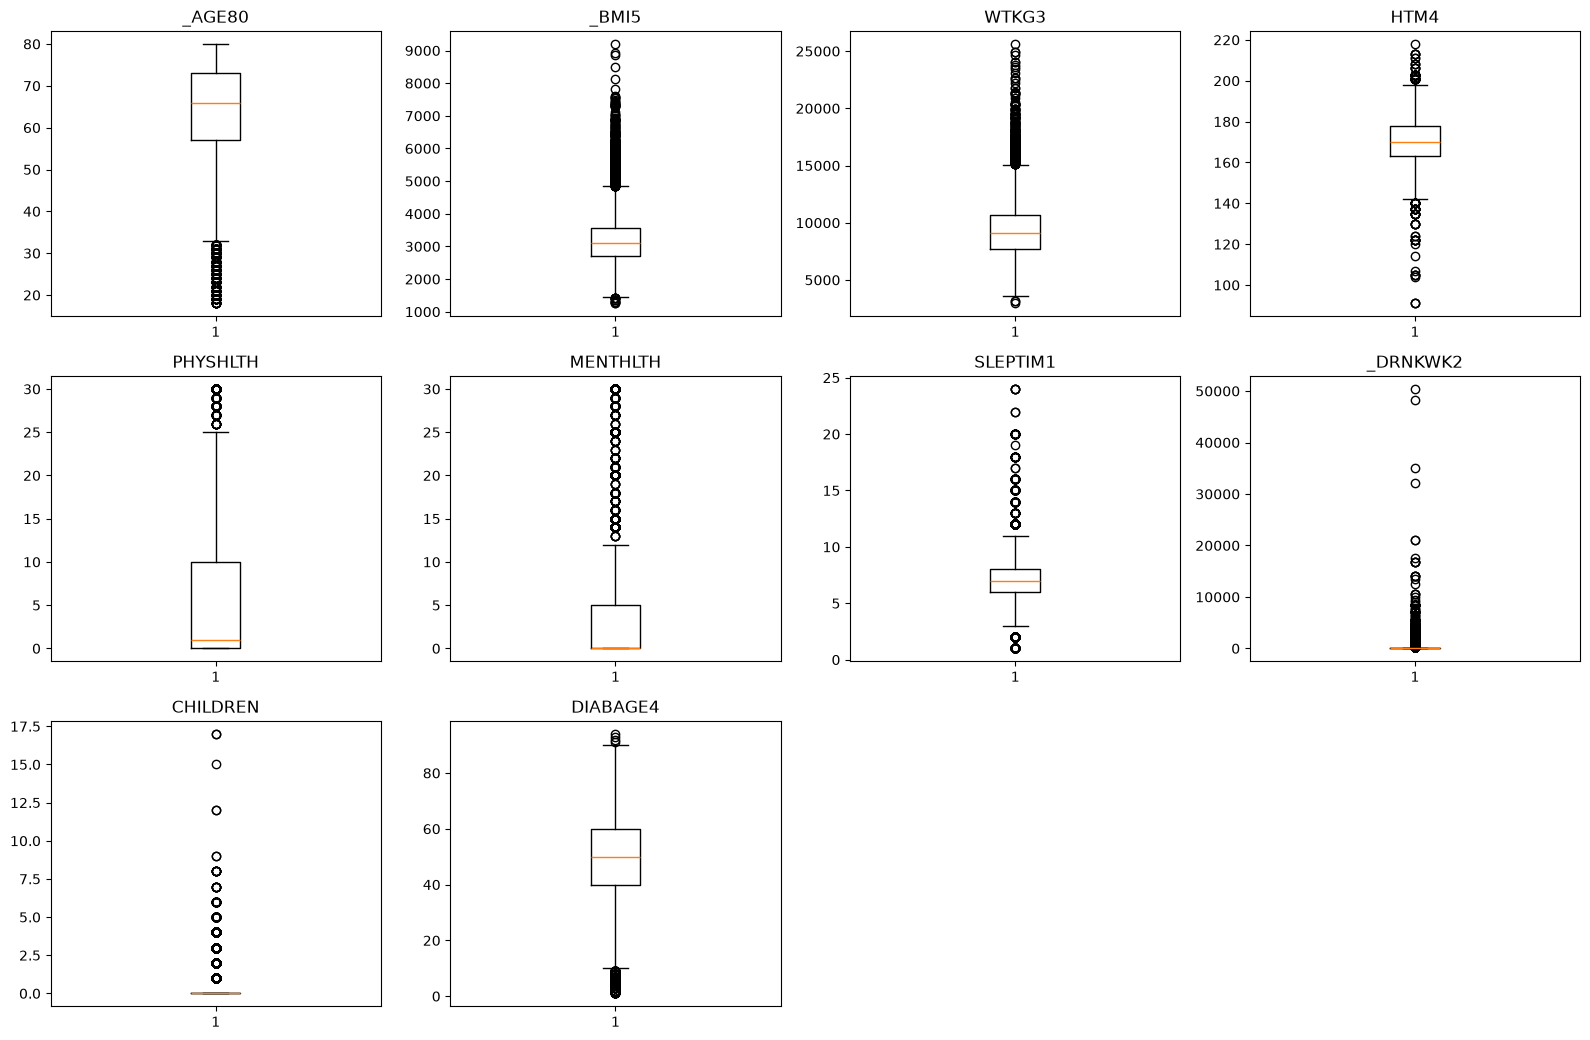

In [53]:
# %% Cek outlier (hanya fitur numerik kontinu)
import matplotlib.pyplot as plt

num_cols = ["_AGE80", "_BMI5", "WTKG3", "HTM4", "PHYSHLTH", "MENTHLTH",
            "SLEPTIM1", "_DRNKWK2", "CHILDREN", "DIABAGE4"]
num_cols = [c for c in num_cols if c in data.columns]

# %% Ringkasan outlier dengan metode IQR
rows = []
for c in num_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[c] < low) | (data[c] > high)).sum()
    rows.append({
        "fitur": c,
        "min": data[c].min(),
        "Q1": q1,
        "median": data[c].median(),
        "Q3": q3,
        "max": data[c].max(),
        "batas_bawah": round(low, 2),
        "batas_atas": round(high, 2),
        "jumlah_outlier": n_out,
        "persen_outlier": round(n_out / len(data) * 100, 2),
    })

outlier_df = pd.DataFrame(rows).sort_values("persen_outlier", ascending=False)
print(outlier_df.to_string(index=False))

# %% Visualisasi boxplot
n = len(num_cols)
ncols = 4
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, c in zip(axes, num_cols):
    ax.boxplot(data[c].dropna(), vert=True)
    ax.set_title(c)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

GENHLTH    -0.217602
_AGE80     -0.186062
EMPLOY1    -0.181459
CVDSTRK3    0.179919
DIFFWALK    0.174387
PHYSHLTH   -0.167940
CHCCOPD3    0.163220
CHCKDNY2    0.147594
HAVARTH4    0.119597
PNEUVAC4    0.116740
DEAF        0.116251
DIFFALON    0.112847
VETERAN3    0.108043
SEXVAR      0.107349
DIFFDRES    0.099050
PERSDOC3   -0.092929
INCOME3     0.090202
BLIND       0.085740
_SMOKER3    0.079353
CHCOCNC1    0.079264
Name: _MICHD, dtype: float64


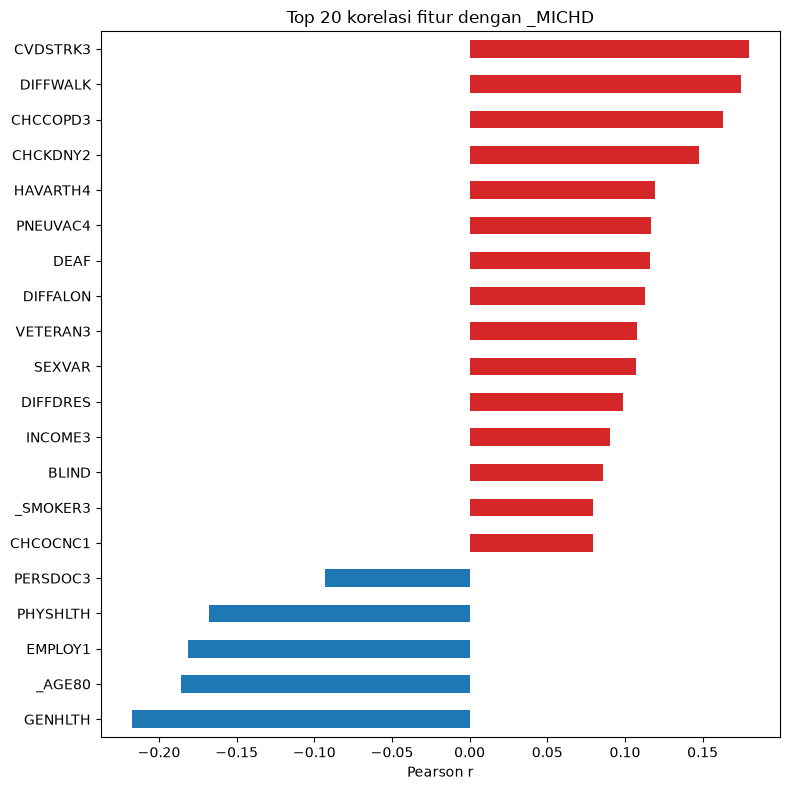

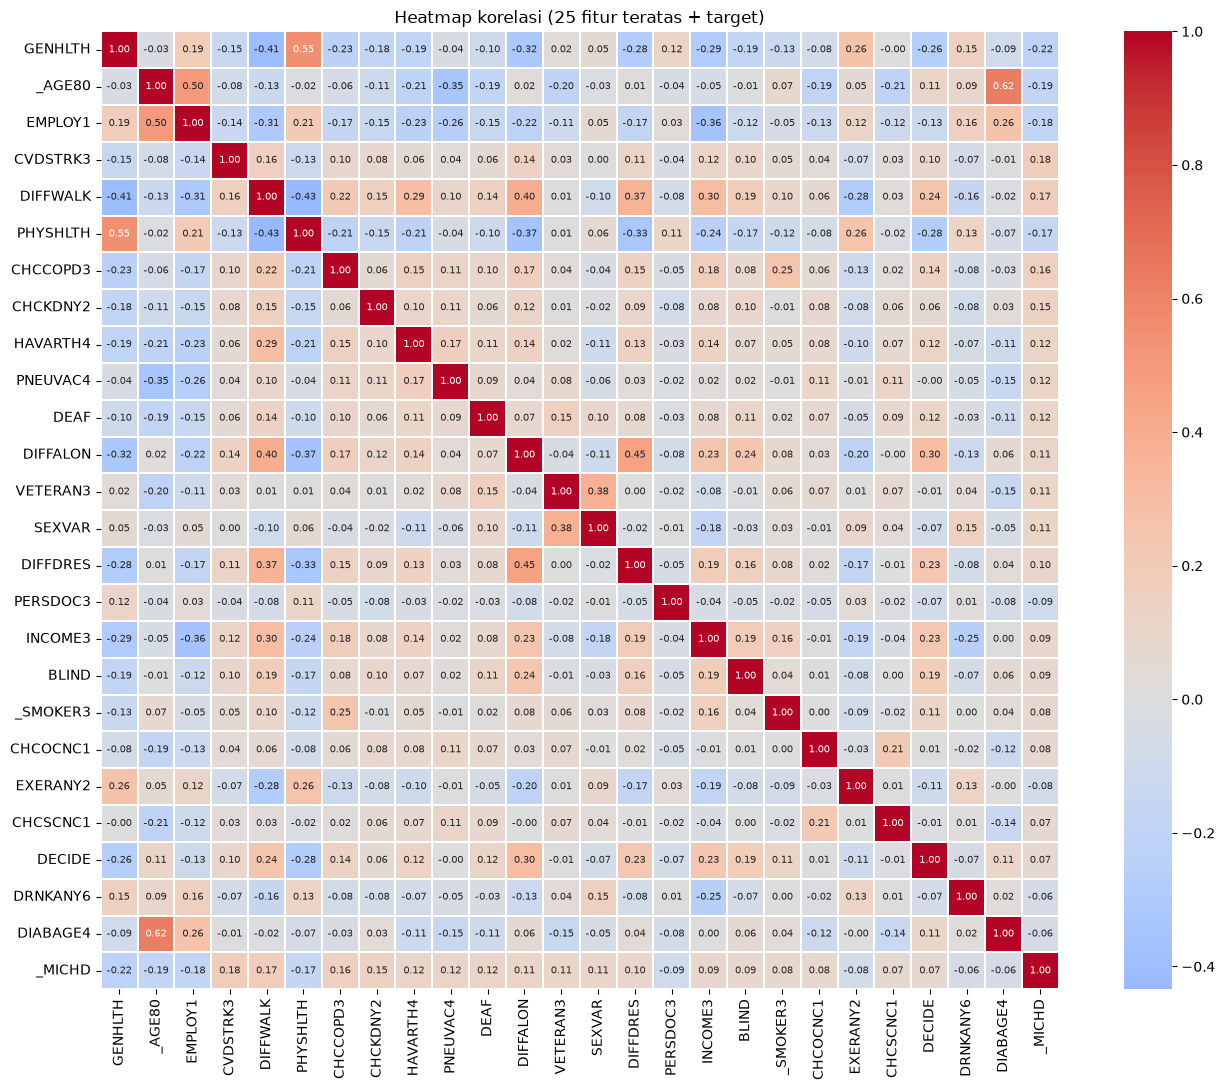

fitur_1 fitur_2        r
  _BMI5   WTKG3 0.846603


In [54]:
# %%
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pastikan target numerik 0/1
df_corr = data.copy()
df_corr["_MICHD"] = df_corr["_MICHD"].astype(int)

corr = df_corr.corr(method="pearson", numeric_only=True)

# %%
# 1) Korelasi tiap fitur terhadap target (_MICHD)
target_corr = corr["_MICHD"].drop("_MICHD").sort_values(key=abs, ascending=False)
print(target_corr.head(20))

plt.figure(figsize=(8, 8))
top = target_corr.head(20).sort_values()
colors = ["tab:red" if v > 0 else "tab:blue" for v in top]
top.plot(kind="barh", color=colors)
plt.title("Top 20 korelasi fitur dengan _MICHD")
plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

# %%
# 2) Heatmap korelasi: 25 fitur teratas terhadap target + target
top_cols = target_corr.head(25).index.tolist() + ["_MICHD"]
plt.figure(figsize=(14, 11))
sns.heatmap(df_corr[top_cols].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            square=True, linewidths=0.3)
plt.title("Heatmap korelasi (25 fitur teratas + target)")
plt.tight_layout(); plt.show()

# %%
# 3) Pasangan fitur dengan korelasi antar-fitur tinggi (|r| > 0.8)
feat_corr = corr.drop(index="_MICHD", columns="_MICHD")
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))

high_pairs = (upper.stack()
                   .rename("r")
                   .reset_index()
                   .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"}))
high_pairs = high_pairs[high_pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False)
print(high_pairs.to_string(index=False))

In [55]:
# Cek value counts untuk semua fitur
for col in data.columns:
    print(f"\n{'=' * 60}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique(dropna=False)}")
    print(f"{'=' * 60}")

    print(data[col].value_counts(dropna=False).to_string())


Fitur: _STATE
Jumlah nilai unik: 51
_STATE
53.0    1749
39.0    1452
24.0    1347
48.0    1191
12.0    1125
36.0    1103
27.0    1086
20.0     925
51.0     892
18.0     890
45.0     853
55.0     844
4.0      840
13.0     792
23.0     753
19.0     748
31.0     731
26.0     730
15.0     702
29.0     611
46.0     603
54.0     595
6.0      585
5.0      573
49.0     565
9.0      547
25.0     529
22.0     506
33.0     503
40.0     502
1.0      498
30.0     489
47.0     483
8.0      463
35.0     453
50.0     438
34.0     437
44.0     402
16.0     395
28.0     395
21.0     386
17.0     331
10.0     328
41.0     328
42.0     322
2.0      318
38.0     310
37.0     301
56.0     296
32.0     221
11.0     168

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2022    30953
2023     1681

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    17273
2.0    15361

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    3130
70.0    1176
65.0    1161
75.0    1120
68.0    1119
67.0    1111
72.0    1097
74.0    1075
69.0   

In [56]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     27824
1.0      2477
2.0      1449
3.0       561
4.0       202
5.0        66
6.0        33
8.0         8
7.0         7
12.0        2
17.0        2
9.0         2
15.0        1
Name: count, dtype: int64

In [57]:
# Konversi nilai ke satuan aktual
data["HTM4"] = data["HTM4"] / 100
data["WTKG3"] = data["WTKG3"] / 100
data["_BMI5"] = data["_BMI5"] / 100

In [58]:
data

,_STATE,IYEAR,SEXVAR,_AGE80,MARITAL,_EDUCAG,INCOME3,EMPLOY1,RENTHOM1,VETERAN3,...,DIFFWALK,DIFFDRES,DIFFALON,_SMOKER3,USENOW3,_DRNKWK2,_RFBING6,DRNKANY6,FLUSHOT7,PNEUVAC4
3,1.0,2022,2.0,80.0,3.0,1.0,6.0,7.0,1.0,2.0,...,1.0,2.0,1.0,3.0,2.0,5.397605e-79,1.0,2.0,1.0,1.0
4,1.0,2022,2.0,68.0,2.0,2.0,2.0,8.0,2.0,2.0,...,2.0,2.0,2.0,2.0,3.0,2.300000e+01,1.0,1.0,1.0,1.0
5,1.0,2022,2.0,73.0,3.0,3.0,5.0,7.0,1.0,2.0,...,2.0,2.0,2.0,3.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
7,1.0,2022,1.0,76.0,1.0,4.0,6.0,7.0,1.0,1.0,...,2.0,2.0,2.0,3.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
8,1.0,2022,2.0,80.0,3.0,3.0,2.0,7.0,1.0,2.0,...,1.0,2.0,1.0,3.0,3.0,7.000000e+01,1.0,1.0,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59333,56.0,2023,1.0,69.0,3.0,2.0,6.0,7.0,1.0,2.0,...,2.0,2.0,2.0,4.0,3.0,5.397605e-79,1.0,2.0,2.0,2.0
59334,56.0,2023,2.0,80.0,2.0,2.0,2.0,7.0,2.0,2.0,...,1.0,2.0,2.0,3.0,3.0,5.397605e-79,1.0,2.0,1.0,1.0
59335,56.0,2023,1.0,57.0,2.0,3.0,6.0,1.0,1.0,2.0,...,2.0,2.0,2.0,1.0,1.0,5.397605e-79,1.0,2.0,2.0,2.0
59338,56.0,2023,2.0,59.0,3.0,4.0,2.0,2.0,1.0,2.0,...,2.0,2.0,2.0,4.0,3.0,6.000000e+02,1.0,1.0,1.0,1.0


In [59]:
for col in data.columns:
    print(f"\n{'='*50}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique()}")
    print("="*50)

    print(data[col].value_counts(dropna=False))


Fitur: _STATE
Jumlah nilai unik: 51
_STATE
53.0    1749
39.0    1452
24.0    1347
48.0    1191
12.0    1125
36.0    1103
27.0    1086
20.0     925
51.0     892
18.0     890
45.0     853
55.0     844
4.0      840
13.0     792
23.0     753
19.0     748
31.0     731
26.0     730
15.0     702
29.0     611
46.0     603
54.0     595
6.0      585
5.0      573
49.0     565
9.0      547
25.0     529
22.0     506
33.0     503
40.0     502
1.0      498
30.0     489
47.0     483
8.0      463
35.0     453
50.0     438
34.0     437
44.0     402
16.0     395
28.0     395
21.0     386
17.0     331
10.0     328
41.0     328
42.0     322
2.0      318
38.0     310
37.0     301
56.0     296
32.0     221
11.0     168
Name: count, dtype: int64

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2022    30953
2023     1681
Name: count, dtype: int64

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    17273
2.0    15361
Name: count, dtype: int64

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    3130
70.0    1176
65.0   

In [60]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def to_binary(df, col, yes, no):
    """Petakan yes -> 1, no -> 0. Semua kode lain (7, 9, dst) jadi NaN."""
    df[col] = df[col].map({yes: 1, no: 0})

def onehot(df, col, invalid=(7, 9), prefix=None):
    """
    1) Kode invalid (Don't know / Refused) -> NaN
    2) One-hot encoding
    3) Baris yang aslinya NaN tetap NaN di semua kolom dummy
       (bukan 0 semua)
    """
    prefix = prefix or col
    s = df[col].replace(list(invalid), np.nan).astype("Int64")
    mask = s.isna()
    dummies = pd.get_dummies(s, prefix=prefix, dtype=float)
    dummies[mask] = np.nan
    return pd.concat([df.drop(columns=col), dummies], axis=1)

# ------------------------------------------------------------
# BINARY (1 = Yes -> 1, 2 = No -> 0)
# ------------------------------------------------------------
# SEXVAR: 1 = Male, 2 = Female  ->  Male = 0, Female = 1
to_binary(data, "SEXVAR", yes=2, no=1)

# VETERAN3: 1 = Yes, 2 = No
to_binary(data, "VETERAN3", yes=1, no=2)

# _URBSTAT: 1 = Urban, 2 = Rural  ->  Urban = 1, Rural = 0
to_binary(data, "_URBSTAT", yes=1, no=2)

# FLUSHOT7, PNEUVAC4: 1 = Yes, 2 = No
for col in ["FLUSHOT7", "PNEUVAC4"]:
    to_binary(data, col, yes=1, no=2)

# _RFBING6: 1 = No, 2 = Yes, 9 = DK/Refused  (KEBALIKAN dari yang lain!)
to_binary(data, "_RFBING6", yes=2, no=1)

# Semua yang kodenya 1 = Yes, 2 = No
binary_features = [
    "MEDCOST1", "EXERANY2", "CVDSTRK3", "CHCSCNC1", "CHCOCNC1",
    "CHCCOPD3", "ADDEPEV3", "CHCKDNY2", "HAVARTH4",
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
]
for col in binary_features:
    to_binary(data, col, yes=1, no=2)

# ------------------------------------------------------------
# ORDINAL
# ------------------------------------------------------------
# GENHLTH: 1 = Excellent ... 5 = Poor; 7, 9 -> NaN
data["GENHLTH"] = data["GENHLTH"].replace([7, 9], np.nan)

# ------------------------------------------------------------
# ONE-HOT (nominal)
# ------------------------------------------------------------
data = onehot(data, "MARITAL")
data = onehot(data, "EMPLOY1",   invalid=(9,))
data = onehot(data, "RENTHOM1",  invalid=(7, 9))
data = onehot(data, "_IMPRACE",  invalid=())          # 1-6, tidak ada kode invalid
data = onehot(data, "PERSDOC3",  invalid=(7, 9))
data = onehot(data, "_ASTHMS1",  invalid=(9,))
data = onehot(data, "_SMOKER3",  invalid=(9,))
data = onehot(data, "USENOW3",   invalid=(7, 9))

# ------------------------------------------------------------
# VERIFIKASI
# ------------------------------------------------------------
all_binary = (
    ["SEXVAR", "VETERAN3", "_URBSTAT", "FLUSHOT7", "PNEUVAC4", "_RFBING6"]
    + binary_features
)
for col in all_binary:
    vals = set(data[col].dropna().unique())
    assert vals <= {0, 1}, f"{col} punya nilai tak terduga: {vals}"
    print(f"{col:10s} ->", data[col].value_counts(dropna=False).to_dict())

SEXVAR     -> {0: 17273, 1: 15361}
VETERAN3   -> {0: 26698, 1: 5936}
_URBSTAT   -> {1: 27833, 0: 4801}
FLUSHOT7   -> {1: 21579, 0: 11055}
PNEUVAC4   -> {1: 21105, 0: 11529}
_RFBING6   -> {0: 30336, 1: 2298}
MEDCOST1   -> {0: 30193, 1: 2441}
EXERANY2   -> {1: 20766, 0: 11868}
CVDSTRK3   -> {0: 29493, 1: 3141}
CHCSCNC1   -> {0: 29135, 1: 3499}
CHCOCNC1   -> {0: 27099, 1: 5535}
CHCCOPD3   -> {0: 27889, 1: 4745}
ADDEPEV3   -> {0: 24228, 1: 8406}
CHCKDNY2   -> {0: 28224, 1: 4410}
HAVARTH4   -> {1: 17451, 0: 15183}
DEAF       -> {0: 27943, 1: 4691}
BLIND      -> {0: 29627, 1: 3007}
DECIDE     -> {0: 27733, 1: 4901}
DIFFWALK   -> {0: 21954, 1: 10680}
DIFFDRES   -> {0: 30126, 1: 2508}
DIFFALON   -> {0: 28489, 1: 4145}


In [61]:
data = data.drop(columns=['WTKG3','HTM4'])

In [ ]:
data = data[(data['CHILDREN'] < 30) | (data['CHILDREN'].isna())]


In [63]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     27824
1.0      2477
2.0      1449
3.0       561
4.0       202
5.0        66
6.0        33
8.0         8
7.0         7
12.0        2
17.0        2
9.0         2
15.0        1
Name: count, dtype: int64

In [64]:
data.info()
data["_MICHD"] = data["_MICHD"].map({1.0: 1, 2.0: 0}).astype(int)

<class 'pandas.DataFrame'>
Index: 32634 entries, 3 to 59339
Data columns (total 75 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      32634 non-null  float64
 1   IYEAR       32634 non-null  int64  
 2   SEXVAR      32634 non-null  int64  
 3   _AGE80      32634 non-null  float64
 4   _EDUCAG     32634 non-null  float64
 5   INCOME3     32634 non-null  float64
 6   VETERAN3    32634 non-null  int64  
 7   CHILDREN    32634 non-null  float64
 8   _URBSTAT    32634 non-null  int64  
 9   _BMI5       32634 non-null  float64
 10  DIABETE4    32634 non-null  float64
 11  PRIMINSR    32634 non-null  float64
 12  MEDCOST1    32634 non-null  int64  
 13  CHECKUP1    32634 non-null  float64
 14  GENHLTH     32634 non-null  float64
 15  PHYSHLTH    32634 non-null  float64
 16  MENTHLTH    32634 non-null  float64
 17  SLEPTIM1    32634 non-null  float64
 18  EXERANY2    32634 non-null  int64  
 19  CVDSTRK3    32634 non-null  int64  
 20  

In [65]:
# 1 = minum alkohol dalam 30 hari terakhir, 0 = tidak
data['DRNKANY6'] = data['DRNKANY6'].map({1.0: 1, 2.0: 0})

print(data['DRNKANY6'].value_counts(dropna=False))

DRNKANY6
0    20376
1    12258
Name: count, dtype: int64


In [66]:
data.to_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2022_diabetes.csv", index=False)

In [67]:
data['_MICHD'].value_counts()

_MICHD
0    25480
1     7154
Name: count, dtype: int64

In [68]:
data['_MICHD'].value_counts()

_MICHD
0    25480
1     7154
Name: count, dtype: int64

In [69]:
data.info()

<class 'pandas.DataFrame'>
Index: 32634 entries, 3 to 59339
Data columns (total 75 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      32634 non-null  float64
 1   IYEAR       32634 non-null  int64  
 2   SEXVAR      32634 non-null  int64  
 3   _AGE80      32634 non-null  float64
 4   _EDUCAG     32634 non-null  float64
 5   INCOME3     32634 non-null  float64
 6   VETERAN3    32634 non-null  int64  
 7   CHILDREN    32634 non-null  float64
 8   _URBSTAT    32634 non-null  int64  
 9   _BMI5       32634 non-null  float64
 10  DIABETE4    32634 non-null  float64
 11  PRIMINSR    32634 non-null  float64
 12  MEDCOST1    32634 non-null  int64  
 13  CHECKUP1    32634 non-null  float64
 14  GENHLTH     32634 non-null  float64
 15  PHYSHLTH    32634 non-null  float64
 16  MENTHLTH    32634 non-null  float64
 17  SLEPTIM1    32634 non-null  float64
 18  EXERANY2    32634 non-null  int64  
 19  CVDSTRK3    32634 non-null  int64  
 20  